In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import holidays

In [2]:
# Cargar los datos de ventas y competencia desde data/raw/entrenamiento

# Cargar los archivos CSV en DataFrames
ventas_df = pd.read_csv("../data/raw/entrenamiento/ventas.csv")
competencia_df = pd.read_csv("../data/raw/entrenamiento/competencia.csv")

# Convertir las fechas a datetime
ventas_df["fecha"] = pd.to_datetime(ventas_df["fecha"])
competencia_df["fecha"] = pd.to_datetime(competencia_df["fecha"])

# Mostrar las primeras filas para verificar
print("Ventas:")
print(ventas_df.head())
print("\nCompetencia:")
print(competencia_df.head())

Ventas:
       fecha producto_id                            nombre categoria  \
0 2021-10-25    PROD_001          Nike Air Zoom Pegasus 40   Running   
1 2021-10-25    PROD_002              Adidas Ultraboost 23   Running   
2 2021-10-25    PROD_003               Asics Gel Nimbus 25   Running   
3 2021-10-25    PROD_004  New Balance Fresh Foam X 1080v12   Running   
4 2021-10-25    PROD_005                Nike Dri-FIT Miler   Running   

         subcategoria  precio_base  es_estrella  unidades_vendidas  \
0  Zapatillas Running          115         True                  6   
1  Zapatillas Running          135         True                 10   
2  Zapatillas Running           85        False                  2   
3  Zapatillas Running           75        False                  2   
4        Ropa Running           35        False                  2   

   precio_venta  ingresos  
0        118.36    710.16  
1        136.82   1368.20  
2         84.93    169.86  
3         75.42    150.84 

In [3]:
resumen_calidad = pd.DataFrame({
    "tipo": ventas_df.dtypes.astype(str),
    "no_nulos": ventas_df.notna().sum(),
    "nulos": ventas_df.isna().sum(),
    "porcentaje_nulos": (ventas_df.isna().mean() * 100).round(2),
    "valores_unicos": ventas_df.nunique(dropna=True),
})

filas_duplicadas = ventas_df.duplicated().sum()
duplicados_fecha_producto = ventas_df.duplicated(
    subset=["fecha", "producto_id"]
).sum()
fechas_parseadas = pd.to_datetime(ventas_df["fecha"], errors="coerce")
fechas_invalidas = fechas_parseadas.isna().sum()
columnas_texto = [
    columna
    for columna in ventas_df.columns
    if pd.api.types.is_string_dtype(ventas_df[columna].dtype)
]
cadenas_vacias = ventas_df[columnas_texto].apply(
    lambda columna: columna.str.strip().eq("").sum()
)
columnas_numericas = ventas_df.select_dtypes(include="number").columns
valores_negativos = ventas_df[columnas_numericas].lt(0).sum()
inconsistencias_ingresos = (
    ventas_df["ingresos"]
    - ventas_df["precio_venta"] * ventas_df["unidades_vendidas"]
).abs().gt(0.01).sum()
descriptivos = ventas_df.describe(include="all").T

print(f"Dimensiones: {ventas_df.shape[0]} filas x {ventas_df.shape[1]} columnas")
print(f"Rango de fechas: {fechas_parseadas.min().date()} a {fechas_parseadas.max().date()}")
print(f"Filas duplicadas completas: {filas_duplicadas}")
print(f"Claves fecha-producto duplicadas: {duplicados_fecha_producto}")
print(f"Fechas no interpretables: {fechas_invalidas}")
print(f"Inconsistencias ingresos vs. precio_venta x unidades: {inconsistencias_ingresos}")
print("\nCadenas vacías por columna de texto:")
print(cadenas_vacias.to_string())
print("\nValores negativos por columna numérica:")
print(valores_negativos.to_string())
print("\nCalidad por variable:")
print(resumen_calidad.to_string())
print("\nEstadísticos descriptivos:")
print(descriptivos.to_string())

Dimensiones: 3552 filas x 10 columnas
Rango de fechas: 2021-10-25 a 2024-11-30
Filas duplicadas completas: 0
Claves fecha-producto duplicadas: 0
Fechas no interpretables: 0
Inconsistencias ingresos vs. precio_venta x unidades: 0

Cadenas vacías por columna de texto:
producto_id     0
nombre          0
categoria       0
subcategoria    0

Valores negativos por columna numérica:
precio_base          0
unidades_vendidas    0
precio_venta         0
ingresos             0

Calidad por variable:
                             tipo  no_nulos  nulos  porcentaje_nulos  valores_unicos
fecha              datetime64[us]      3552      0               0.0             148
producto_id                   str      3552      0               0.0              24
nombre                        str      3552      0               0.0              24
categoria                     str      3552      0               0.0               4
subcategoria                  str      3552      0               0.0            

In [4]:
resumen_calidad_competencia = pd.DataFrame({
    "tipo": competencia_df.dtypes.astype(str),
    "no_nulos": competencia_df.notna().sum(),
    "nulos": competencia_df.isna().sum(),
    "porcentaje_nulos": (competencia_df.isna().mean() * 100).round(2),
    "valores_unicos": competencia_df.nunique(dropna=True),
})

filas_duplicadas_competencia = competencia_df.duplicated().sum()
duplicados_fecha_producto_competencia = competencia_df.duplicated(
    subset=["fecha", "producto_id"]
).sum()
fechas_competencia_parseadas = pd.to_datetime(
    competencia_df["fecha"], errors="coerce"
)
fechas_invalidas_competencia = fechas_competencia_parseadas.isna().sum()
columnas_texto_competencia = [
    columna
    for columna in competencia_df.columns
    if pd.api.types.is_string_dtype(competencia_df[columna].dtype)
]
cadenas_vacias_competencia = competencia_df[columnas_texto_competencia].apply(
    lambda columna: columna.str.strip().eq("").sum()
)
columnas_numericas_competencia = competencia_df.select_dtypes(
    include="number"
).columns
valores_negativos_competencia = competencia_df[
    columnas_numericas_competencia
].lt(0).sum()
descriptivos_competencia = competencia_df.describe(include="all").T

print(
    f"Dimensiones: {competencia_df.shape[0]} filas x "
    f"{competencia_df.shape[1]} columnas"
)
print(
    "Rango de fechas: "
    f"{fechas_competencia_parseadas.min().date()} a "
    f"{fechas_competencia_parseadas.max().date()}"
)
print(f"Filas duplicadas completas: {filas_duplicadas_competencia}")
print(
    "Claves fecha-producto duplicadas: "
    f"{duplicados_fecha_producto_competencia}"
)
print(f"Fechas no interpretables: {fechas_invalidas_competencia}")
print("\nCadenas vacías por columna de texto:")
print(cadenas_vacias_competencia.to_string())
print("\nValores negativos por columna numérica:")
print(valores_negativos_competencia.to_string())
print("\nCalidad por variable:")
print(resumen_calidad_competencia.to_string())
print("\nEstadísticos descriptivos:")
print(descriptivos_competencia.to_string())

Dimensiones: 3552 filas x 5 columnas
Rango de fechas: 2021-10-25 a 2024-11-30
Filas duplicadas completas: 0
Claves fecha-producto duplicadas: 0
Fechas no interpretables: 0

Cadenas vacías por columna de texto:
producto_id    0

Valores negativos por columna numérica:
Amazon          0
Decathlon       0
Deporvillage    0

Calidad por variable:
                        tipo  no_nulos  nulos  porcentaje_nulos  valores_unicos
fecha         datetime64[us]      3552      0               0.0             148
producto_id              str      3552      0               0.0              24
Amazon               float64      3552      0               0.0            3125
Decathlon            float64      3552      0               0.0            3001
Deporvillage         float64      3552      0               0.0            3105

Estadísticos descriptivos:
               count unique       top freq                 mean                  min                  25%                  50%                  75%

In [5]:
ventas_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3552 entries, 0 to 3551
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   fecha              3552 non-null   datetime64[us]
 1   producto_id        3552 non-null   str           
 2   nombre             3552 non-null   str           
 3   categoria          3552 non-null   str           
 4   subcategoria       3552 non-null   str           
 5   precio_base        3552 non-null   int64         
 6   es_estrella        3552 non-null   bool          
 7   unidades_vendidas  3552 non-null   int64         
 8   precio_venta       3552 non-null   float64       
 9   ingresos           3552 non-null   float64       
dtypes: bool(1), datetime64[us](1), float64(2), int64(2), str(4)
memory usage: 433.1 KB


In [6]:
competencia_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3552 entries, 0 to 3551
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   fecha         3552 non-null   datetime64[us]
 1   producto_id   3552 non-null   str           
 2   Amazon        3552 non-null   float64       
 3   Decathlon     3552 non-null   float64       
 4   Deporvillage  3552 non-null   float64       
dtypes: datetime64[us](1), float64(3), str(1)
memory usage: 166.6 KB


In [7]:
df = ventas_df.merge(
    competencia_df,
    on=["fecha", "producto_id"],
    how="left",
    validate="one_to_one",
)

print(f"Dimensiones de df: {df.shape[0]} filas x {df.shape[1]} columnas")
print("Nulos en los precios de competencia después de la unión:")
print(df[["Amazon", "Decathlon", "Deporvillage"]].isna().sum().to_string())
df.head()

Dimensiones de df: 3552 filas x 13 columnas
Nulos en los precios de competencia después de la unión:
Amazon          0
Decathlon       0
Deporvillage    0


,fecha,producto_id,nombre,categoria,subcategoria,precio_base,es_estrella,unidades_vendidas,precio_venta,ingresos,Amazon,Decathlon,Deporvillage
0,2021-10-25,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,6,118.36,710.16,82.96,111.88,97.43
1,2021-10-25,PROD_002,Adidas Ultraboost 23,Running,Zapatillas Running,135,True,10,136.82,1368.20,112.56,108.61,115.58
2,2021-10-25,PROD_003,Asics Gel Nimbus 25,Running,Zapatillas Running,85,False,2,84.93,169.86,79.79,78.44,80.11
3,2021-10-25,PROD_004,New Balance Fresh Foam X 1080v12,Running,Zapatillas Running,75,False,2,75.42,150.84,72.60,67.29,74.45
4,2021-10-25,PROD_005,Nike Dri-FIT Miler,Running,Ropa Running,35,False,2,35.87,71.74,37.71,33.60,33.07


## 1. Ventas diarias por año y Black Friday
Agrega las unidades vendidas por fecha y dibuja una serie temporal independiente para cada año, señalando su Black Friday.

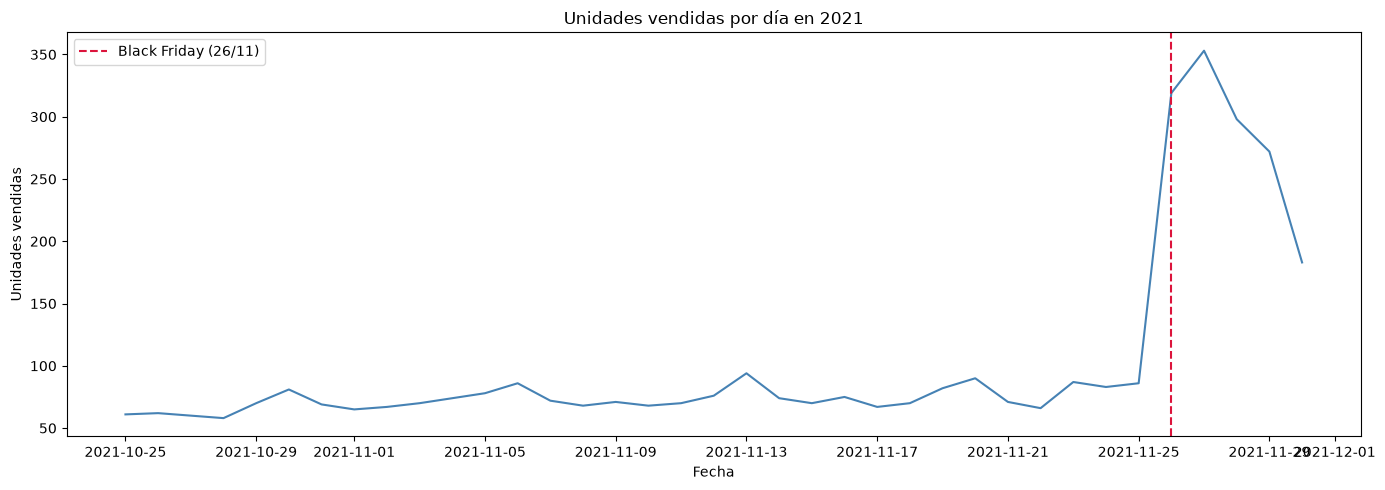

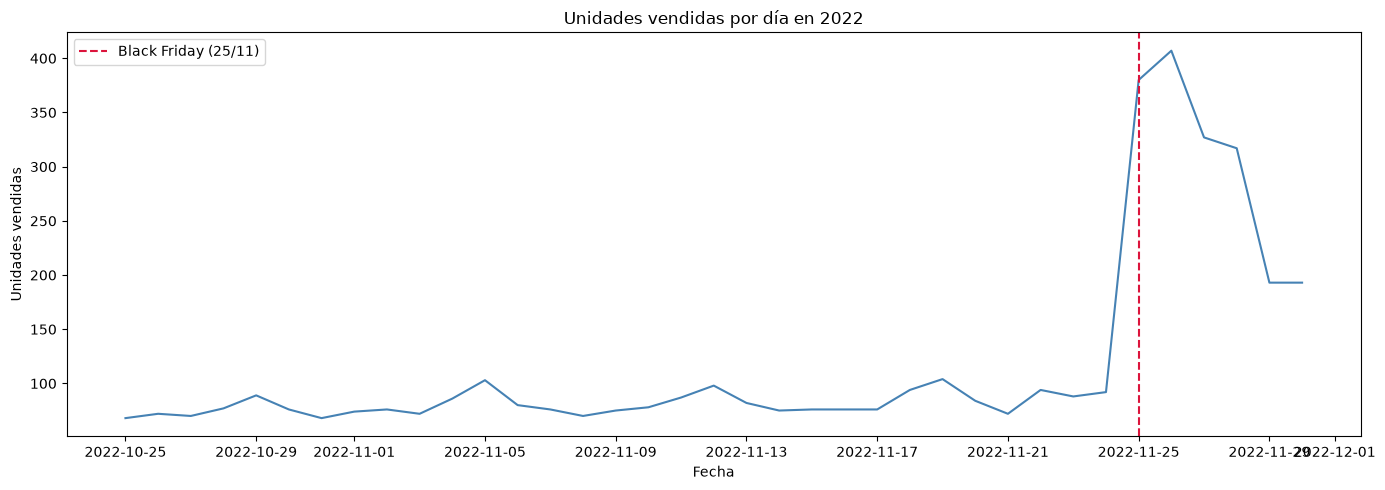

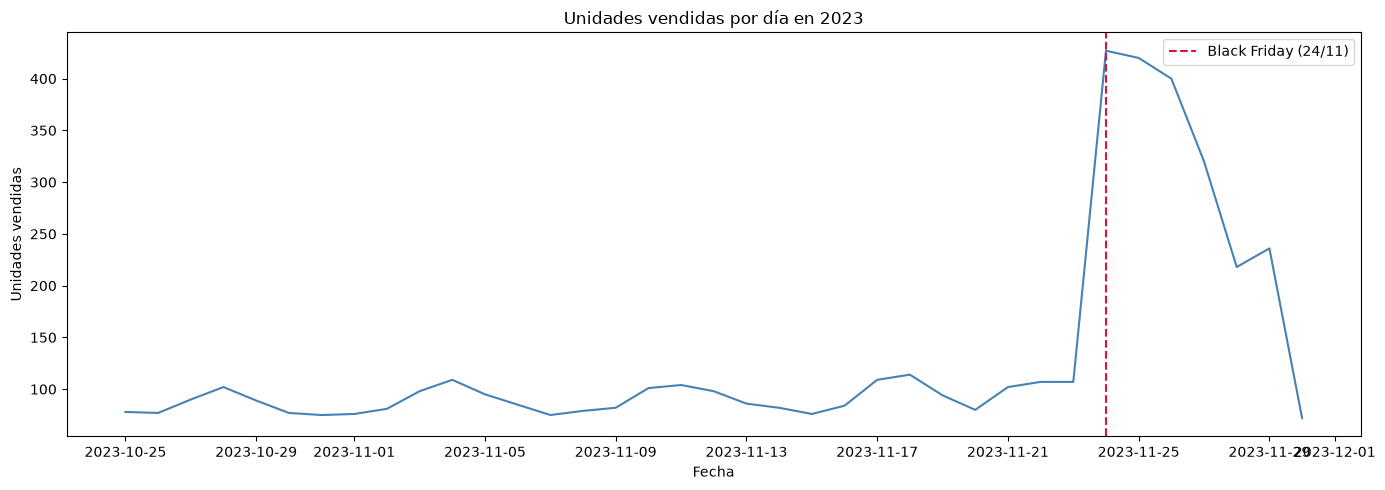

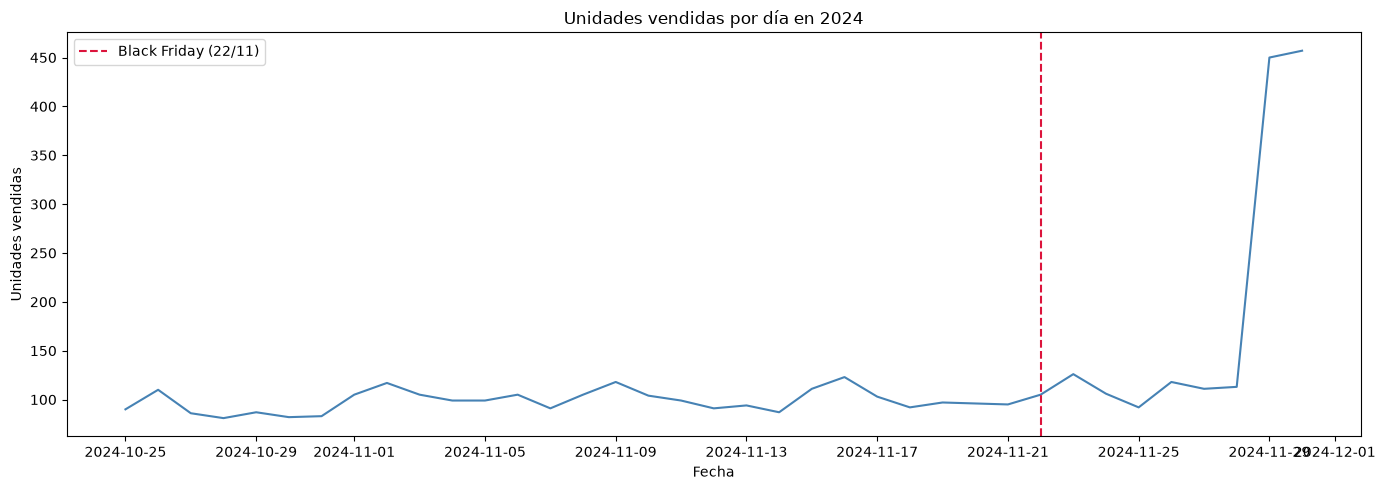

In [8]:
# Sumar las unidades por fecha para evitar una línea por producto.
ventas_diarias = df.groupby("fecha", as_index=False)["unidades_vendidas"].sum()

# Dibujar una figura independiente para cada año disponible.
for anio in sorted(ventas_diarias["fecha"].dt.year.unique()):
    ventas_anuales = ventas_diarias[
        ventas_diarias["fecha"].dt.year == anio
    ]
    figura, eje = plt.subplots(figsize=(14, 5))
    sns.lineplot(
        data=ventas_anuales,
        x="fecha",
        y="unidades_vendidas",
        ax=eje,
        color="steelblue",
    )

    # El Black Friday corresponde al cuarto viernes de noviembre.
    viernes_noviembre = pd.date_range(
        start=f"{anio}-11-01", end=f"{anio}-11-30", freq="W-FRI"
    )
    fecha_black_friday = viernes_noviembre[3]
    eje.axvline(
        fecha_black_friday,
        color="crimson",
        linestyle="--",
        label=f"Black Friday ({fecha_black_friday:%d/%m})",
    )
    eje.set(
        title=f"Unidades vendidas por día en {anio}",
        xlabel="Fecha",
        ylabel="Unidades vendidas",
    )
    eje.legend()
    figura.tight_layout()
    plt.show()

## 2. Unidades vendidas por día de la semana
Suma las unidades por día de la semana para comparar los patrones de venta entre lunes y domingo.

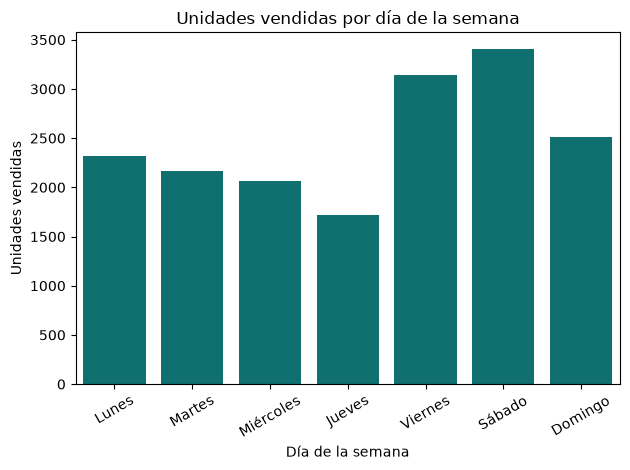

In [9]:
# Sumar unidades por número de día, de lunes (0) a domingo (6).
ventas_por_dia = (
    df.groupby(df["fecha"].dt.dayofweek)["unidades_vendidas"]
    .sum()
    .reindex(range(7), fill_value=0)
    .rename_axis("dia_numero")
    .reset_index(name="unidades_vendidas")
)

# Asignar etiquetas en español y conservar el orden semanal.
dias_semana = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
ventas_por_dia["dia_semana"] = ventas_por_dia["dia_numero"].map(
    dict(enumerate(dias_semana))
)
sns.barplot(
    data=ventas_por_dia,
    x="dia_semana",
    y="unidades_vendidas",
    order=dias_semana,
    color="teal",
)
plt.title("Unidades vendidas por día de la semana")
plt.xlabel("Día de la semana")
plt.ylabel("Unidades vendidas")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 3. Unidades vendidas por categoría
Agrupa las unidades por categoría y las ordena para identificar las áreas con mayor volumen.

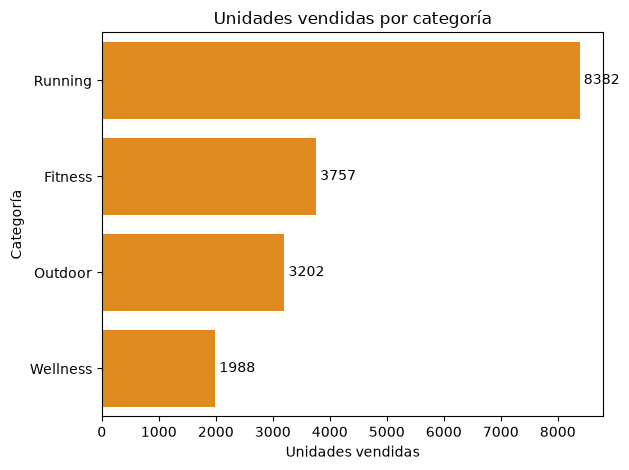

In [10]:
# Sumar las unidades por categoría y ordenar de mayor a menor.
ventas_por_categoria = (
    df.groupby("categoria", as_index=False)["unidades_vendidas"]
    .sum()
    .sort_values("unidades_vendidas", ascending=False)
)
eje = sns.barplot(
    data=ventas_por_categoria,
    x="unidades_vendidas",
    y="categoria",
    color="darkorange",
    
) 
eje.bar_label(eje.containers[0], fmt="%.0f", padding=3)

plt.title("Unidades vendidas por categoría")
plt.xlabel("Unidades vendidas")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

## 4. Unidades vendidas por subcategoría
Suma las unidades por subcategoría y muestra primero las de mayor volumen.

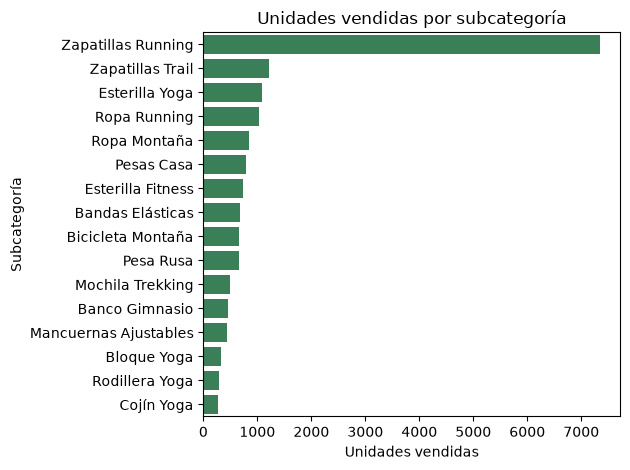

In [11]:
# Sumar y ordenar las unidades vendidas por subcategoría.
ventas_por_subcategoria = (
    df.groupby("subcategoria", as_index=False)["unidades_vendidas"]
    .sum()
    .sort_values("unidades_vendidas", ascending=False)
)
sns.barplot(
    data=ventas_por_subcategoria,
    x="unidades_vendidas",
    y="subcategoria",
    color="seagreen",
)
plt.title("Unidades vendidas por subcategoría")
plt.xlabel("Unidades vendidas")
plt.ylabel("Subcategoría")
plt.tight_layout()
plt.show()

## 5. Top 10 productos por unidades vendidas
Agrega las unidades por producto y compara los diez productos con más ventas.

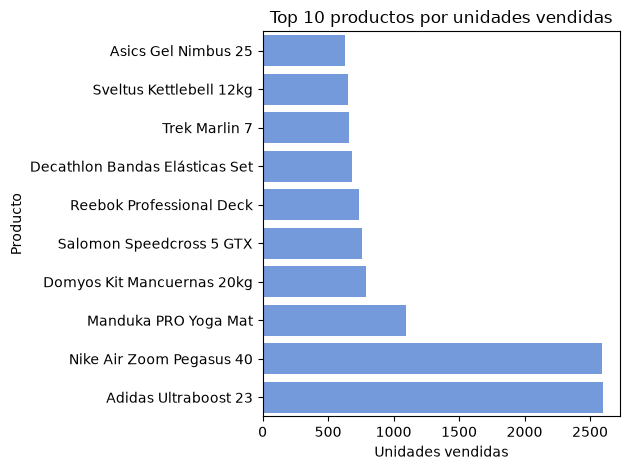

In [12]:
# Agregar ventas por identificador y nombre del producto.
top_productos = (
    df.groupby(["producto_id", "nombre"], as_index=False)["unidades_vendidas"]
    .sum()
    .nlargest(10, "unidades_vendidas")
    .sort_values("unidades_vendidas", ascending=True)
)
sns.barplot(
    data=top_productos,
    x="unidades_vendidas",
    y="nombre",
    color="cornflowerblue",
)
plt.title("Top 10 productos por unidades vendidas")
plt.xlabel("Unidades vendidas")
plt.ylabel("Producto")
plt.tight_layout()
plt.show()

## 6. Densidad de precios: venta y Amazon
Compara las distribuciones de `precio_venta` y `Amazon` con curvas de densidad sobre la misma escala.

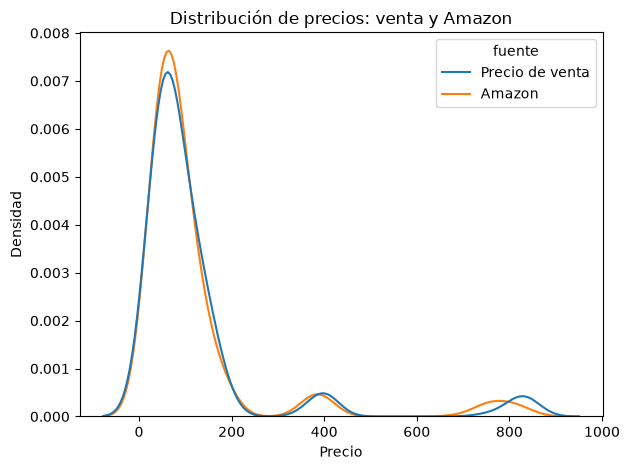

In [13]:
# Preparar ambos precios en formato largo y excluir valores ausentes.
precios_comparados = (
    df[["precio_venta", "Amazon"]]
    .rename(columns={"precio_venta": "Precio de venta", "Amazon": "Amazon"})
    .melt(var_name="fuente", value_name="precio")
    .dropna(subset=["precio"])
)

# Dibujar ambas densidades con normalización independiente.
sns.kdeplot(
    data=precios_comparados,
    x="precio",
    hue="fuente",
    common_norm=False,
    fill=False,
)
plt.title("Distribución de precios: venta y Amazon")
plt.xlabel("Precio")
plt.ylabel("Densidad")
plt.tight_layout()
plt.show()

## 7. Variables temporales y de calendario
Crea en df las variables temporales del calendario y los festivos nacionales de España.

In [14]:
# Si la celda se ejecuta sola, crea lo mínimo necesario para que funcione.
if "pd" not in globals():
    import pandas as pd
if "holidays" not in globals():
    import holidays

if "df" not in globals():
    if "ventas_df" not in globals() or "competencia_df" not in globals():
        ventas_df = pd.read_csv("../data/raw/entrenamiento/ventas.csv")
        competencia_df = pd.read_csv("../data/raw/entrenamiento/competencia.csv")
        ventas_df["fecha"] = pd.to_datetime(ventas_df["fecha"])
        competencia_df["fecha"] = pd.to_datetime(competencia_df["fecha"])
    df = ventas_df.merge(
        competencia_df,
        on=["fecha", "producto_id"],
        how="left",
        validate="one_to_one",
    )

if not pd.api.types.is_datetime64_any_dtype(df["fecha"]):
    df["fecha"] = pd.to_datetime(df["fecha"])

# Calendario nacional de España con holidays.
anios_holidays = sorted(df["fecha"].dt.year.dropna().unique().tolist())
festivos_es = holidays.country_holidays("ES", years=anios_holidays)
festivos_normales = pd.to_datetime(list(festivos_es.keys())).normalize()

# Black Friday y Cyber Monday por año.
fechas_black_friday = {}
fechas_cyber_monday = {}
for anio in anios_holidays:
    dias_noviembre = pd.date_range(
        start=pd.Timestamp(year=int(anio), month=11, day=1),
        end=pd.Timestamp(year=int(anio), month=11, day=30),
        freq="D",
    )
    viernes_noviembre = dias_noviembre[dias_noviembre.weekday == 4]
    fechas_black_friday[int(anio)] = viernes_noviembre[3]
    fechas_cyber_monday[int(anio)] = viernes_noviembre[3] + pd.Timedelta(days=3)

black_friday_por_anio = pd.Series(
    {anio: pd.Timestamp(fecha).normalize() for anio, fecha in fechas_black_friday.items()}
)
cyber_monday_por_anio = pd.Series(
    {anio: pd.Timestamp(fecha).normalize() for anio, fecha in fechas_cyber_monday.items()}
)

# Variables temporales y de calendario pedidas.
df["año"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month
df["dia_mes"] = df["fecha"].dt.day
df["dia_semana"] = df["fecha"].dt.dayofweek
df["trimestre"] = df["fecha"].dt.quarter
df["semana_año"] = df["fecha"].dt.isocalendar().week.astype("int16")
df["es_fin_semana"] = df["fecha"].dt.dayofweek.isin([5, 6]).astype("int8")
df["es_festivo"] = df["fecha"].dt.normalize().isin(festivos_normales).astype("int8")
df["es_laborable"] = (
    ~df["es_fin_semana"].astype(bool) & ~df["es_festivo"].astype(bool)
).astype("int8")
df["es_inicio_mes"] = df["fecha"].dt.day.le(3).astype("int8")
df["es_fin_mes"] = df["fecha"].dt.day.ge(df["fecha"].dt.days_in_month - 2).astype("int8")
df["es_Black_Friday"] = (
    df["año"].map(black_friday_por_anio).eq(df["fecha"].dt.normalize())
).astype("int8")
df["es_Cyber_Monday"] = (
    df["año"].map(cyber_monday_por_anio).eq(df["fecha"].dt.normalize())
).astype("int8")

# Resumen final de las nuevas variables creadas.
variables_nuevas = [
    "año",
    "mes",
    "dia_mes",
    "dia_semana",
    "trimestre",
    "semana_año",
    "es_fin_semana",
    "es_festivo",
    "es_laborable",
    "es_inicio_mes",
    "es_fin_mes",
    "es_Black_Friday",
    "es_Cyber_Monday",
]
resumen_variables = pd.DataFrame({
    "variable": variables_nuevas,
    "valores_distintos": [df[col].nunique(dropna=False) for col in variables_nuevas],
})

print(f"df.shape = {df.shape}")
print(resumen_variables.to_string(index=False))

df.shape = (3552, 26)
       variable  valores_distintos
            año                  4
            mes                  2
        dia_mes                 31
     dia_semana                  7
      trimestre                  1
     semana_año                  6
  es_fin_semana                  2
     es_festivo                  2
   es_laborable                  2
  es_inicio_mes                  2
     es_fin_mes                  2
es_Black_Friday                  2
es_Cyber_Monday                  2


In [15]:
df.head()


,fecha,producto_id,nombre,categoria,subcategoria,precio_base,es_estrella,unidades_vendidas,precio_venta,ingresos,...,dia_semana,trimestre,semana_año,es_fin_semana,es_festivo,es_laborable,es_inicio_mes,es_fin_mes,es_Black_Friday,es_Cyber_Monday
0,2021-10-25,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,6,118.36,710.16,...,0,4,43,0,0,1,0,0,0,0
1,2021-10-25,PROD_002,Adidas Ultraboost 23,Running,Zapatillas Running,135,True,10,136.82,1368.20,...,0,4,43,0,0,1,0,0,0,0
2,2021-10-25,PROD_003,Asics Gel Nimbus 25,Running,Zapatillas Running,85,False,2,84.93,169.86,...,0,4,43,0,0,1,0,0,0,0
3,2021-10-25,PROD_004,New Balance Fresh Foam X 1080v12,Running,Zapatillas Running,75,False,2,75.42,150.84,...,0,4,43,0,0,1,0,0,0,0
4,2021-10-25,PROD_005,Nike Dri-FIT Miler,Running,Ropa Running,35,False,2,35.87,71.74,...,0,4,43,0,0,1,0,0,0,0


### 8. Lags de unidades vendidas y media móvil de 7 días
Calcula lags y media móvil agrupados por producto y año, elimina filas incompletas y muestra el tamaño final.

In [16]:
# Inicializa df desde los datos originales si aún no se ejecutaron las celdas anteriores.
if "df" not in globals():
    if "pd" not in globals():
        import pandas as pd
    if "ventas_df" not in globals() or "competencia_df" not in globals():
        ventas_df = pd.read_csv("../data/raw/entrenamiento/ventas.csv")
        competencia_df = pd.read_csv("../data/raw/entrenamiento/competencia.csv")
        ventas_df["fecha"] = pd.to_datetime(ventas_df["fecha"])
        competencia_df["fecha"] = pd.to_datetime(competencia_df["fecha"])
    df = ventas_df.merge(
        competencia_df,
        on=["fecha", "producto_id"],
        how="left",
        validate="one_to_one",
    )

# Ordena por producto y fecha antes de calcular las variables temporales.
df.sort_values(["producto_id", "fecha"], inplace=True)

# Agrupa por producto y año para evitar mezclar historiales.
grupos_producto_anio = df.groupby(
    ["producto_id", df["fecha"].dt.year]
)["unidades_vendidas"]

# Crea los lags del 1 al 7 dentro de cada grupo.
for lag in range(1, 8):
    df[f"unidades_vendidas_lag{lag}"] = grupos_producto_anio.shift(lag)

# Calcula la media de los siete valores anteriores, excluyendo el actual.
df["unidades_vendidas_ma7"] = grupos_producto_anio.transform(
    lambda valores: valores.shift(1).rolling(window=7, min_periods=7).mean()
)

# Elimina únicamente filas con nulos en las variables nuevas.
columnas_nuevas = [
    f"unidades_vendidas_lag{lag}" for lag in range(1, 8)
] + ["unidades_vendidas_ma7"]
filas_antes = len(df)
df.dropna(subset=columnas_nuevas, inplace=True)
print(f"Filas eliminadas: {filas_antes - len(df)}")

# Muestra la forma final del dataframe.
print(f"df.shape = {df.shape}")

Filas eliminadas: 672
df.shape = (2880, 34)


In [17]:
df.head()


,fecha,producto_id,nombre,categoria,subcategoria,precio_base,es_estrella,unidades_vendidas,precio_venta,ingresos,...,es_Black_Friday,es_Cyber_Monday,unidades_vendidas_lag1,unidades_vendidas_lag2,unidades_vendidas_lag3,unidades_vendidas_lag4,unidades_vendidas_lag5,unidades_vendidas_lag6,unidades_vendidas_lag7,unidades_vendidas_ma7
168,2021-11-01,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,7,115.07,805.49,...,0,0,9.0,12.0,12.0,7.0,8.0,8.0,6.0,8.857143
192,2021-11-02,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,10,116.10,1161.00,...,0,0,7.0,9.0,12.0,12.0,7.0,8.0,8.0,9.000000
216,2021-11-03,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,11,114.58,1260.38,...,0,0,10.0,7.0,9.0,12.0,12.0,7.0,8.0,9.285714
240,2021-11-04,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,12,112.23,1346.76,...,0,0,11.0,10.0,7.0,9.0,12.0,12.0,7.0,9.714286
264,2021-11-05,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,10,113.81,1138.10,...,0,0,12.0,11.0,10.0,7.0,9.0,12.0,12.0,10.428571


## 8. Cálculo del porcentaje de descuento

Añadimos la variable de descuento sin alterar las columnas existentes.

In [18]:
# Calcular el descuento porcentual con la fórmula solicitada.
df['descuento_porcentaje'] = (df['precio_venta'] - df['precio_base']) / df['precio_base'] * 100

# Mostrar una fila por producto (máximo 10) y la forma del DataFrame.
display(
    df[['producto_id', 'nombre', 'precio_base', 'precio_venta', 'descuento_porcentaje']]
    .drop_duplicates(subset='producto_id')
    .head(10)
)
df.shape

,producto_id,nombre,precio_base,precio_venta,descuento_porcentaje
168,PROD_001,Nike Air Zoom Pegasus 40,115,115.07,0.060870
169,PROD_002,Adidas Ultraboost 23,135,136.00,0.740741
170,PROD_003,Asics Gel Nimbus 25,85,85.14,0.164706
171,PROD_004,New Balance Fresh Foam X 1080v12,75,76.74,2.320000
172,PROD_005,Nike Dri-FIT Miler,35,34.89,-0.314286
173,PROD_006,Adidas Own The Run Jacket,65,64.67,-0.507692
174,PROD_007,Puma Velocity Nitro 2,70,71.38,1.971429
175,PROD_008,Reebok Floatride Energy 5,65,63.09,-2.938462
176,PROD_009,Bowflex SelectTech 552,400,397.99,-0.502500
177,PROD_010,Domyos BM900,175,172.48,-1.440000


(2880, 35)

## 10. Precio de competencia y ratio de precio

In [19]:
# Si la celda se ejecuta sola, crea el dataframe mínimo necesario para continuar.
if "pd" not in globals():
    import pandas as pd
if "df" not in globals():
    if "ventas_df" not in globals() or "competencia_df" not in globals():
        ventas_df = pd.read_csv("../data/raw/entrenamiento/ventas.csv")
        competencia_df = pd.read_csv("../data/raw/entrenamiento/competencia.csv")
        ventas_df["fecha"] = pd.to_datetime(ventas_df["fecha"])
        competencia_df["fecha"] = pd.to_datetime(competencia_df["fecha"])
    df = ventas_df.merge(
        competencia_df,
        on=["fecha", "producto_id"],
        how="left",
        validate="one_to_one",
    )

if not pd.api.types.is_datetime64_any_dtype(df["fecha"]):
    df["fecha"] = pd.to_datetime(df["fecha"])

# Variable precio_competencia: promedio de Amazon, Decathlon y Deporvillage
df["precio_competencia"] = df[["Amazon", "Decathlon", "Deporvillage"]].mean(axis=1)

# Variable ratio_precio: nuestro precio entre el precio promedio de la competencia
df["ratio_precio"] = df["precio_venta"] / df["precio_competencia"]

# Eliminar las variables de Amazon, Decathlon y Deporvillage
df = df.drop(columns=["Amazon", "Decathlon", "Deporvillage"])

# Mostrar las primeras filas para verificar
print(f"df.shape: {df.shape}")
df[["fecha", "producto_id", "precio_venta", "precio_competencia", "ratio_precio"]].head()


df.shape: (2880, 34)


,fecha,producto_id,precio_venta,precio_competencia,ratio_precio
168,2021-11-01,PROD_001,115.07,95.353333,1.206775
192,2021-11-02,PROD_001,116.10,96.153333,1.207446
216,2021-11-03,PROD_001,114.58,95.240000,1.203066
240,2021-11-04,PROD_001,112.23,96.590000,1.161922
264,2021-11-05,PROD_001,113.81,96.170000,1.183425
